# RouteQ: Quantum-assisted emergency route screening
**Qiskit simulator demonstration | Synthetic scenario | Not quantum hardware**

## Problem
Emergency responders can face multiple route choices with different hazard exposure. This notebook demonstrates how a tiny constrained selection problem can be encoded into a QAOA-style quantum circuit.

**Caution:** this is a learning prototype, not a real emergency routing tool. It does not claim quantum advantage.

## 1. Install dependencies
Run in a terminal before opening this notebook:

```bash
pip install -r requirements.txt
```

The notebook uses Qiskit `QuantumCircuit`, `DiagonalGate`, and `Statevector`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.circuit.library import DiagonalGate
from qiskit.quantum_info import Statevector

ROUTES = [
    {"name": "Route A", "risk": 2.0, "minutes": 18, "description": "Main road; moderate congestion"},
    {"name": "Route B", "risk": 1.0, "minutes": 24, "description": "Longer route; lower hazard exposure"},
    {"name": "Route C", "risk": 3.0, "minutes": 15, "description": "Fastest route; higher hazard exposure"},
]
PENALTY = 8.0

def state_costs():
    costs = []
    for idx in range(8):
        bits = [(idx >> q) & 1 for q in range(3)]  # q0, q1, q2
        selected = sum(bits)
        risk = sum(bits[q] * ROUTES[q]["risk"] for q in range(3))
        costs.append(risk + PENALTY * (selected - 1) ** 2)
    return np.asarray(costs, dtype=float)

costs = state_costs()
print("Basis-state objective values:")
for i, cost in enumerate(costs):
    bits = format(i, "03b")
    selected = [ROUTES[q]["name"] for q in range(3) if (i >> q) & 1]
    print(f"|{bits}> -> {selected or 'no route'}; cost={cost:.1f}")

Basis-state objective values:
|000> -> no route; cost=8.0
|001> -> ['Route A']; cost=2.0
|010> -> ['Route B']; cost=1.0
|011> -> ['Route A', 'Route B']; cost=11.0
|100> -> ['Route C']; cost=3.0
|101> -> ['Route A', 'Route C']; cost=13.0
|110> -> ['Route B', 'Route C']; cost=12.0
|111> -> ['Route A', 'Route B', 'Route C']; cost=38.0


## 2. Build the QAOA-style circuit
Each qubit represents one route. Hadamard gates create a uniform superposition. The diagonal cost unitary encodes the objective into relative phases, and the RX mixer changes amplitudes before measurement.

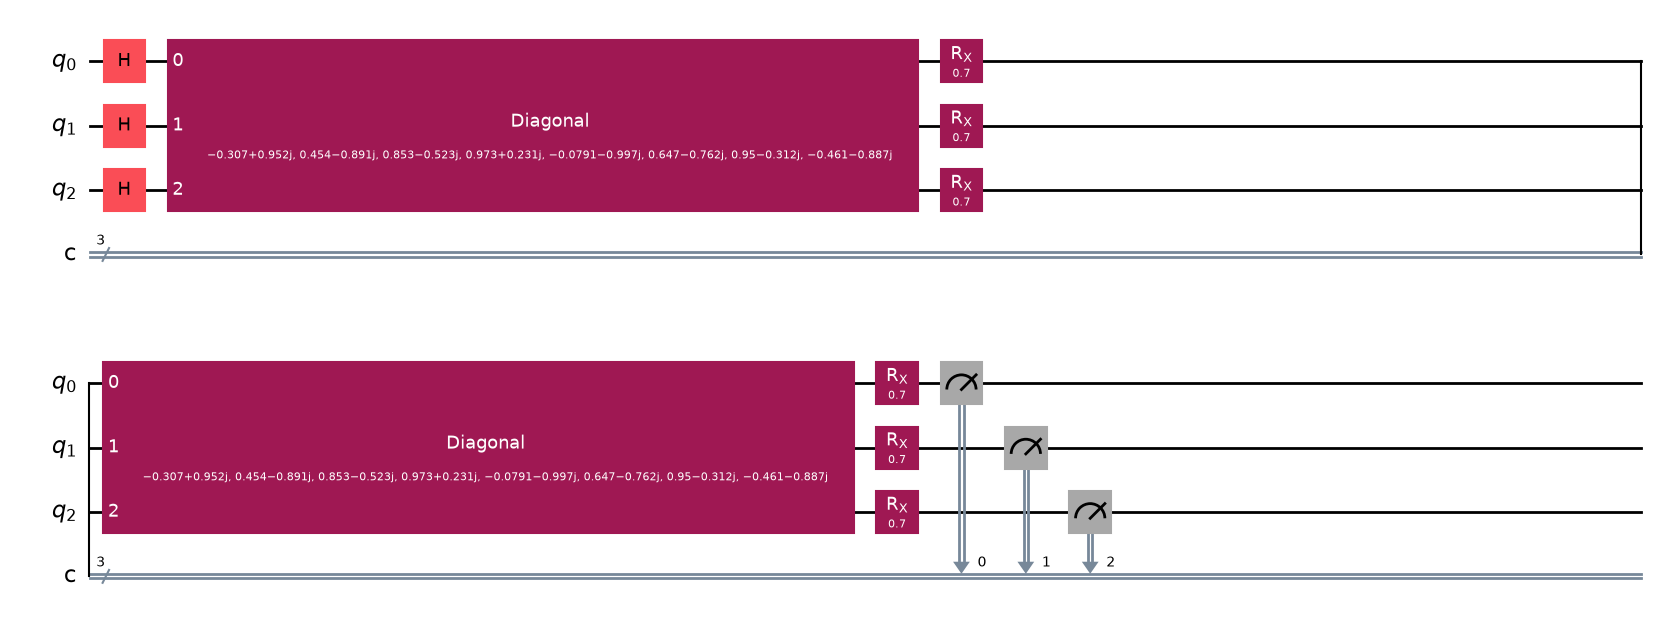

In [2]:
def build_qaoa_circuit(gamma=0.55, beta=0.35, layers=2, measure=True):
    costs = state_costs()
    qc = QuantumCircuit(3, 3) if measure else QuantumCircuit(3)
    qc.h(range(3))
    for _ in range(layers):
        phases = np.exp(-1j * gamma * costs)
        qc.append(DiagonalGate(phases), [0, 1, 2])
        for q in range(3):
            qc.rx(2 * beta, q)
    if measure:
        qc.measure(range(3), range(3))
    return qc

circuit = build_qaoa_circuit()
circuit.draw(output="mpl", fold=24)


## 3. Simulate and sample measurements
We use Qiskit's local statevector simulator, then sample measurement outcomes with a fixed random seed for reproducibility. This is a classical simulation, not an IBM Quantum hardware execution.

Simulator: Qiskit Statevector + seeded sampling | shots=4096
Measurement counts:
111: 1403 (34.3%)
100:  929 (22.7%)
010:  459 (11.2%)
000:  451 (11.0%)
001:  390 (9.5%)
101:  375 (9.2%)
011:   56 (1.4%)
110:   33 (0.8%)


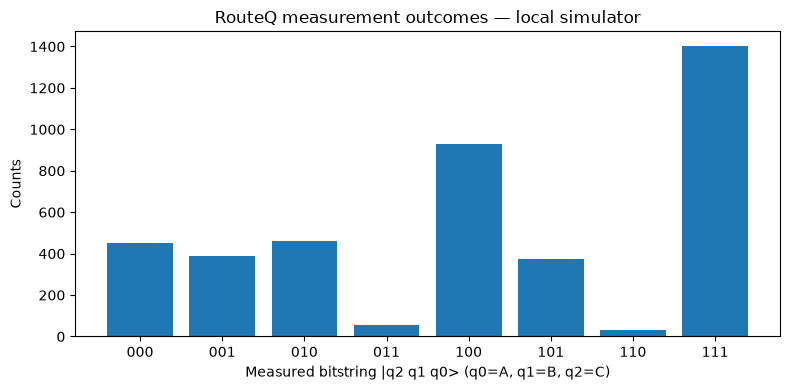

In [3]:
shots = 4096
gamma, beta, layers = 0.55, 0.35, 2
unmeasured = build_qaoa_circuit(gamma=gamma, beta=beta, layers=layers, measure=False)
state = Statevector.from_instruction(unmeasured)
probabilities = np.asarray(state.probabilities(), dtype=float)
rng = np.random.default_rng(7)
samples = rng.choice(8, size=shots, p=probabilities)
counts = {}
for idx in samples:
    # Qiskit basis index is rendered as q2 q1 q0; q0=A, q1=B, q2=C.
    bitstring = format(int(idx), "03b")
    counts[bitstring] = counts.get(bitstring, 0) + 1

print(f"Simulator: Qiskit Statevector + seeded sampling | shots={shots}")
print("Measurement counts:")
for bitstring, count in sorted(counts.items(), key=lambda item: item[1], reverse=True):
    print(f"{bitstring}: {count:4d} ({count/shots:.1%})")

plt.figure(figsize=(8, 4))
keys = [format(i, "03b") for i in range(8)]
vals = [counts.get(k, 0) for k in keys]
plt.bar(keys, vals)
plt.xlabel("Measured bitstring |q2 q1 q0> (q0=A, q1=B, q2=C)")
plt.ylabel("Counts")
plt.title("RouteQ measurement outcomes — local simulator")
plt.tight_layout()
plt.show()

## 4. Interpret the results
Valid one-route states are `001` (Route A), `010` (Route B), and `100` (Route C). All other states are penalized by the objective. The lowest-risk feasible choice for these synthetic inputs is Route B (risk score 1.0), though its illustrative travel time is longer.

**Important:** a sampled outcome is not automatically the optimum. Finite shots, fixed circuit parameters, and the small model mean this is a demonstration of encoding and sampling—not evidence of quantum advantage.

In [4]:
ranked = sorted(range(8), key=lambda i: costs[i])
print("Lowest objective basis states:")
for i in ranked[:5]:
    selected = [ROUTES[q]["name"] for q in range(3) if (i >> q) & 1]
    print(f"|{format(i, '03b')}> -> {selected or 'no route'}; cost={costs[i]:.2f}")

print("\nRoute data:")
for route in ROUTES:
    print(f"{route['name']}: risk={route['risk']}, ETA={route['minutes']} min — {route['description']}")

Lowest objective basis states:
|010> -> ['Route B']; cost=1.00
|001> -> ['Route A']; cost=2.00
|100> -> ['Route C']; cost=3.00
|000> -> no route; cost=8.00
|011> -> ['Route A', 'Route B']; cost=11.00

Route data:
Route A: risk=2.0, ETA=18 min — Main road; moderate congestion
Route B: risk=1.0, ETA=24 min — Longer route; lower hazard exposure
Route C: risk=3.0, ETA=15 min — Fastest route; higher hazard exposure


In [9]:
fig = circuit.draw(output="mpl", fold=24)
fig.savefig("routeq_circuit.png", dpi=300, bbox_inches="tight")

In [10]:
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

fig = plot_histogram(counts)
fig.savefig("routeq_measurement_graph.png", dpi=300, bbox_inches="tight")
plt.show()